# Neural Networks and Deep Learning — Lecture 14: Multimodal and vision-language models; synthesis of the course
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L14_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Image patches in a vision transformer

In [3]:
RES = '../lectures/L14/results/'
import torch, torchvision
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
root = '../data/raw/vision'
os.makedirs(root, exist_ok=True)
ES = torchvision.datasets.EuroSAT(root, download=True)
Z = pd.read_csv(RES + 'eurosat_zeroshot.csv')
CLS = ES.classes
print(len(ES), 'images;', len(Z), 'test images in the lecture split')

27000 images; 5400 test images in the lecture split


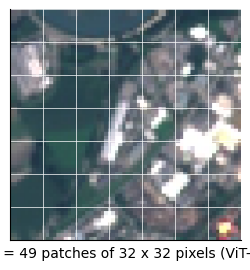

In [4]:
img = ES[int(Z['index'][0])][0].resize((224, 224), Image.NEAREST)
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(img)
for g in range(0, 225, 32):
    ax.axhline(g - 0.5, color='white', lw=0.5); ax.axvline(g - 0.5, color='white', lw=0.5)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('7 x 7 = 49 patches of 32 x 32 pixels (ViT-B/32)')
plt.show()

## §2 CLIP zero-shot on EuroSAT (live on 500 images)

In [5]:
clip = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
def img_emb(idx):
    out = []
    with torch.no_grad():
        for j in range(0, len(idx), 64):
            px = proc(images=[ES[int(i)][0] for i in idx[j:j + 64]], return_tensors='pt')['pixel_values'].to(DEVICE)
            e = clip.get_image_features(pixel_values=px)
            e = e if isinstance(e, torch.Tensor) else e.pooler_output
            out.append(torch.nn.functional.normalize(e.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)
def txt_emb(texts):
    with torch.no_grad():
        t = proc(text=texts, return_tensors='pt', padding=True).to(DEVICE)
        e = clip.get_text_features(**t)
        e = e if isinstance(e, torch.Tensor) else e.pooler_output
        return torch.nn.functional.normalize(e.float(), dim=-1).cpu().numpy()
sample = Z.sample(500, random_state=SEED)
E = img_emb(sample['index'].values)
y = sample['true'].map({c: i for i, c in enumerate(CLS)}).values
NAMES = {'AnnualCrop': 'annual crop land', 'Forest': 'forest', 'HerbaceousVegetation': 'brushland or shrubland', 'Highway': 'highway or road',
         'Industrial': 'industrial buildings or commercial buildings', 'Pasture': 'pasture land', 'PermanentCrop': 'permanent crop land',
         'Residential': 'residential buildings or homes or apartments', 'River': 'river', 'SeaLake': 'lake or sea'}
for tpl in ['{}', 'a satellite photo of {}.']:
    W = txt_emb([tpl.format(NAMES[c] if '{}.' in tpl else c) for c in CLS])
    print(repr(tpl), 'accuracy on 500 images:', round(100 * float(((E @ W.T).argmax(1) == y).mean()), 1), '%')
print('full test set, lecture results:', {c: round(100 * float((Z[c] == Z['true']).mean()), 1) for c in Z.columns if c[:3] in ('B32', 'B16')})

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

'{}' accuracy on 500 images: 31.8 %
'a satellite photo of {}.' accuracy on 500 images: 44.6 %
full test set, lecture results: {'B32_name': 34.1, 'B32_photo': 42.7, 'B32_sat': 44.9, 'B32_ens': 49.1, 'B16_name': 42.4, 'B16_photo': 46.7, 'B16_sat': 55.4, 'B16_ens': 56.4}


§ *Experiment yourself*: write prompts for a class pair that CLIP confuses (pasture and herbaceous vegetation) and check whether the accuracy improves.

## §3 A linear probe with few labels

In [6]:
from sklearn.linear_model import LogisticRegression
train_idx = np.setdiff1d(np.arange(len(ES)), Z['index'].values)
ytr_all = np.array(ES.targets)[train_idx]
rng = np.random.default_rng(SEED)
k16 = np.concatenate([rng.choice(train_idx[ytr_all == c], 16, replace=False) for c in range(10)])
clf = LogisticRegression(max_iter=3000, C=10).fit(img_emb(k16), np.array(ES.targets)[k16])
print('ViT-B/32 probe, 16 images per class, accuracy on the 500-image sample:', round(100 * float((clf.predict(E) == y).mean()), 1), '%')
Fq = pd.read_csv(RES + 'fewshot_eurosat.csv')
print(Fq.groupby(['method', 'k']).acc.mean().mul(100).round(1))

ViT-B/32 probe, 16 images per class, accuracy on the 500-image sample: 79.6 %
method    k   
cnn       4       50.3
          16      78.5
          64      90.9
          128     94.1
cnn_full  2160    97.4
probe     1       59.0
          2       61.6
          4       73.8
          8       80.3
          16      84.7
          32      87.5
          64      90.1
          128     91.6
Name: acc, dtype: float64


## §4 Market regimes from chart images

In [7]:
from sklearn.metrics import roc_auc_score
C = pd.read_csv(RES + 'chart_regime.csv')
Tt = C[C.split == 'test']
print('stress share in test:', round(100 * Tt.stress.mean(), 1), '%')
print({m: round(roc_auc_score(Tt.stress, Tt[m]), 3) for m in ('numeric', 'clip_probe', 'clip_zs', 'vlm_stress')})

stress share in test: 8.4 %
{'numeric': 0.933, 'clip_probe': 0.88, 'clip_zs': 0.907, 'vlm_stress': 0.758}


## §5 Reading tables with a vision-language model

exact answers: 25.0 %
         date  true_10y answer  read
0  2015-05-04      0.48   0.07  0.07
1  2015-05-15      0.74   0.42  0.42
2  2015-12-29      0.77   0.03  0.03
3  2016-02-04      0.40   0.03  0.03
5  2016-07-15     -0.06  -0.33 -0.33


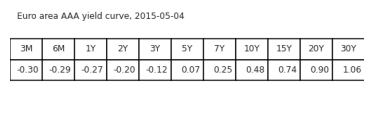

In [8]:
TR = pd.read_csv(RES + 'table_reading.csv')
TR['read'] = pd.to_numeric(TR.answer.str.extract(r'(-?\d+(?:\.\d+)?)')[0], errors='coerce')
print('exact answers:', round(100 * float(np.isclose(TR.read, TR.true_10y, atol=0.001).mean()), 1), '%')
print(TR[~np.isclose(TR.read, TR.true_10y, atol=0.001)].head())
fig, ax = plt.subplots(figsize=(4.6, 1.3))
ax.imshow(Image.open(RES + 'table_example.png'))
ax.axis('off')
plt.show()